# ResScene-CNN v2: Image Classification with a Custom SE-Residual CNN and Grad-CAM Interpretability

**CSC60904 — Deep Learning | Final Individual Assignment (40%) | April 2026 Semester**

**Author:** Mazen Mehna

**Dataset:** Intel Image Classification (Kaggle) — 6 natural-scene classes (*buildings, forest, glacier, mountain, sea, street*), ≈25,000 RGB images at 150×150 resolution.

**Framework:** TensorFlow / Keras (Functional API), Google Colab GPU runtime.

This notebook is organised to mirror the assignment specification:

1. Environment Setup, Hardware Acceleration & Pipeline Mechanics
2. Dataset Ingestion & Advanced Pipeline Engineering (stratified 70/15/15 split, augmentation)
3. Custom Functional API Architecture (4 SE-residual blocks, BatchNorm, Spatial Dropout, GAP)
4. Controlled Training, Optimisation & Dynamic Learning Rates (AdamW, EarlyStopping, ReduceLROnPlateau)
5. Comprehensive Diagnostics & Statistical Evaluation (classification report, confusion matrix, fitting diagnosis)
6. Model Interpretability & Error Analysis (Grad-CAM, top-3 probability charts, critique)
7. *Extension:* Test-Time Augmentation (TTA)
8. *Extension:* Transfer-Learning Benchmark (EfficientNetB0) vs. the custom model

> **Publishing note (Oct 2026):** this is the executed notebook from the run reported in the README (test accuracy 84.47%). When publishing, the student ID was removed and three narrative cells that still contained `[placeholder]` template text (Sections 5(b), 5(c) and 6(c)) were completed using the numbers printed by this run and what the Grad-CAM figure shows. No code cell or output was changed. An earlier run of the same code, used in the written report, reached 85.68%; the gap reflects GPU non-determinism (see the reproducibility checklist at the end).

## 1. Environment Setup, Hardware Acceleration & Pipeline Mechanics

### 1(a) Library imports and GPU verification

We import the full scientific stack used throughout the notebook:

- **TensorFlow / Keras** — model definition (Functional API), `tf.data` input pipelines, training loop and callbacks.
- **NumPy** — array manipulation and the by-hand numerical checks in Section 3(d).
- **Matplotlib / Seaborn** — publication-quality training curves, class-distribution charts and the confusion-matrix heatmap.
- **Scikit-Learn** — the *stratified* train/validation/test split (`train_test_split(..., stratify=...)`) and evaluation metrics (`classification_report`, `confusion_matrix`).
- **OpenCV (`cv2`)** — colour-mapping and alpha-blending of Grad-CAM heatmaps onto the source images in Section 6.

We then *programmatically* verify that a GPU is visible to TensorFlow. Training a 4-block residual CNN on ≈17,500 images/epoch is impractical on CPU; the check below prints the device name and memory details, and warns loudly if no accelerator is found.

In [1]:
# ============================================================
# 1(a) Imports, reproducibility seeds, and GPU verification
# ============================================================
import os, random, json, math, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# ---------- Reproducibility ----------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow version : {tf.__version__}")
print(f"Keras version      : {keras.__version__}")
print(f"NumPy version      : {np.__version__}")

# ---------- GPU verification ----------
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        details = tf.config.experimental.get_device_details(gpu)
        print(f"\n✅ GPU detected: {gpu.name}")
        print(f"   Device name : {details.get('device_name', 'unknown')}")
        print(f"   Compute cap.: {details.get('compute_capability', 'unknown')}")
    # Memory growth avoids TF pre-allocating the whole VRAM block
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError as e:
            print("Memory growth could not be set:", e)
    print("\nLogical GPUs:", tf.config.list_logical_devices('GPU'))
else:
    print("\n⚠️ WARNING: No GPU detected — TensorFlow will fall back to CPU.")
    print("   In Colab: Runtime → Change runtime type → Hardware accelerator → GPU.")
    print("   Training will still run, but each epoch will be dramatically slower.")

TensorFlow version : 2.20.0
Keras version      : 3.13.2
NumPy version      : 2.0.2

✅ GPU detected: /physical_device:GPU:0
   Device name : Tesla T4
   Compute cap.: (7, 5)

Logical GPUs: [LogicalDevice(name='/device:GPU:0', device_type='GPU')]


### 1(b) Why `tf.data.Dataset` instead of a plain Python generator / NumPy arrays?

A naïve pipeline — a Python `for` loop or generator that reads a JPEG from disk, decodes it, and `yield`s a NumPy batch — executes **synchronously on a single CPU thread**. While the CPU is busy with disk I/O and JPEG decoding, the GPU sits **idle**; while the GPU computes the forward/backward pass, the CPU sits idle. The two devices operate in *lock-step alternation*, and total epoch time ≈ (I/O time + compute time). The Python Global Interpreter Lock (GIL) further prevents genuine multi-threaded decoding inside a plain generator.

The `tf.data.Dataset` API removes these bottlenecks through four mechanisms, all used in Section 2:

1. **Parallel mapping** — `.map(decode_fn, num_parallel_calls=tf.data.AUTOTUNE)` executes JPEG decode + resize + rescale across multiple CPU threads in the TensorFlow runtime (outside the GIL), with `AUTOTUNE` dynamically choosing the parallelism level.
2. **Caching** — `.cache()` materialises the *decoded* tensors after the **first** epoch (in RAM, or memory-mapped to a disk file when a filename is given, as we do for the large training split). Epochs 2…N therefore skip file reads and JPEG decoding entirely — the single most expensive stage of an image pipeline.
3. **Prefetching** — `.prefetch(tf.data.AUTOTUNE)` decouples the *producer* (CPU pipeline) from the *consumer* (GPU training step) with an asynchronous buffer: while the GPU processes batch *t*, the CPU is already preparing batch *t+1*. This overlaps I/O with compute, so epoch time → max(I/O time, compute time) instead of their sum.
4. **Graph execution** — the whole pipeline is compiled into the TF graph, avoiding per-batch Python overhead and enabling static optimisations (fusion, vectorised ops).

In short: a NumPy/generator pipeline *starves* the GPU; `tf.data` with `cache()` + `prefetch(AUTOTUNE)` keeps it saturated. We adopt exactly this design below.

## 2. Dataset Ingestion & Advanced Pipeline Engineering

### 2(a) The Intel Image Classification dataset

We use the **Intel Image Classification** dataset (published on Kaggle by P. Bansal, originally from an Intel scene-classification challenge): ≈25,000 RGB natural-scene photographs at **150×150** resolution across **6 classes** — `buildings`, `forest`, `glacier`, `mountain`, `sea`, `street`.

**Why this dataset satisfies the brief:**

- MNIST and Fashion-MNIST are prohibited; at 150×150×3 this dataset has **~66× the spatial resolution of CIFAR-10** (32×32), satisfying the *higher spatial resolution / geometric complexity* requirement.
- The larger images make **Grad-CAM heatmaps genuinely interpretable** — a 150×150 scene contains distinguishable foreground/background structure (ridgelines, façades, horizons), unlike a 32×32 thumbnail.
- Several class pairs have **known semantic overlap** (glacier↔mountain share snow/rock/sky composition; buildings↔street co-occur in urban scenes), which provides rich material for the confusion-matrix error analysis in Section 5 and the Grad-CAM critique in Section 6.

The Kaggle archive ships pre-split as `seg_train` (≈14k), `seg_test` (≈3k) and an unlabelled `seg_pred` folder. Because the assignment requires our **own strict stratified 70/15/15 split**, we *pool all labelled images* (`seg_train` + `seg_test`, ignoring the unlabelled `seg_pred`) and re-split them ourselves in 2(b).

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset downloaded to: /kaggle/input/intel-image-classification
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Total labelled images pooled: 17034


,count
buildings,2628
forest,2745
glacier,2957
mountain,3037
sea,2784
street,2883


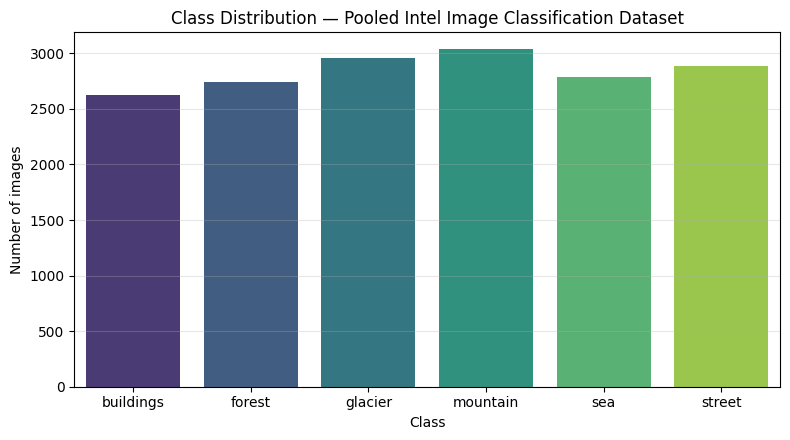

In [2]:
# ============================================================
# 2(a) Download the dataset and index every labelled image
# ============================================================
import kagglehub

DATA_ROOT = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Dataset downloaded to:", DATA_ROOT)

LABELLED_DIRS = [
    os.path.join(DATA_ROOT, "seg_train", "seg_train"),
    os.path.join(DATA_ROOT, "seg_test",  "seg_test"),
]

CLASS_NAMES = sorted(os.listdir(LABELLED_DIRS[0]))   # alphabetical → stable label ids
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_ID = {c: i for i, c in enumerate(CLASS_NAMES)}
print("Classes:", CLASS_NAMES)

all_paths, all_labels = [], []
for d in LABELLED_DIRS:
    for cname in CLASS_NAMES:
        cdir = os.path.join(d, cname)
        for fname in os.listdir(cdir):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                all_paths.append(os.path.join(cdir, fname))
                all_labels.append(CLASS_TO_ID[cname])

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f"Total labelled images pooled: {len(all_paths)}")

# Per-class counts + bar chart
counts = pd.Series(all_labels).value_counts().sort_index()
counts.index = CLASS_NAMES
display(counts.to_frame("count"))

plt.figure(figsize=(8, 4.5))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index,
            palette="viridis", legend=False)
plt.title("Class Distribution — Pooled Intel Image Classification Dataset")
plt.xlabel("Class"); plt.ylabel("Number of images")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

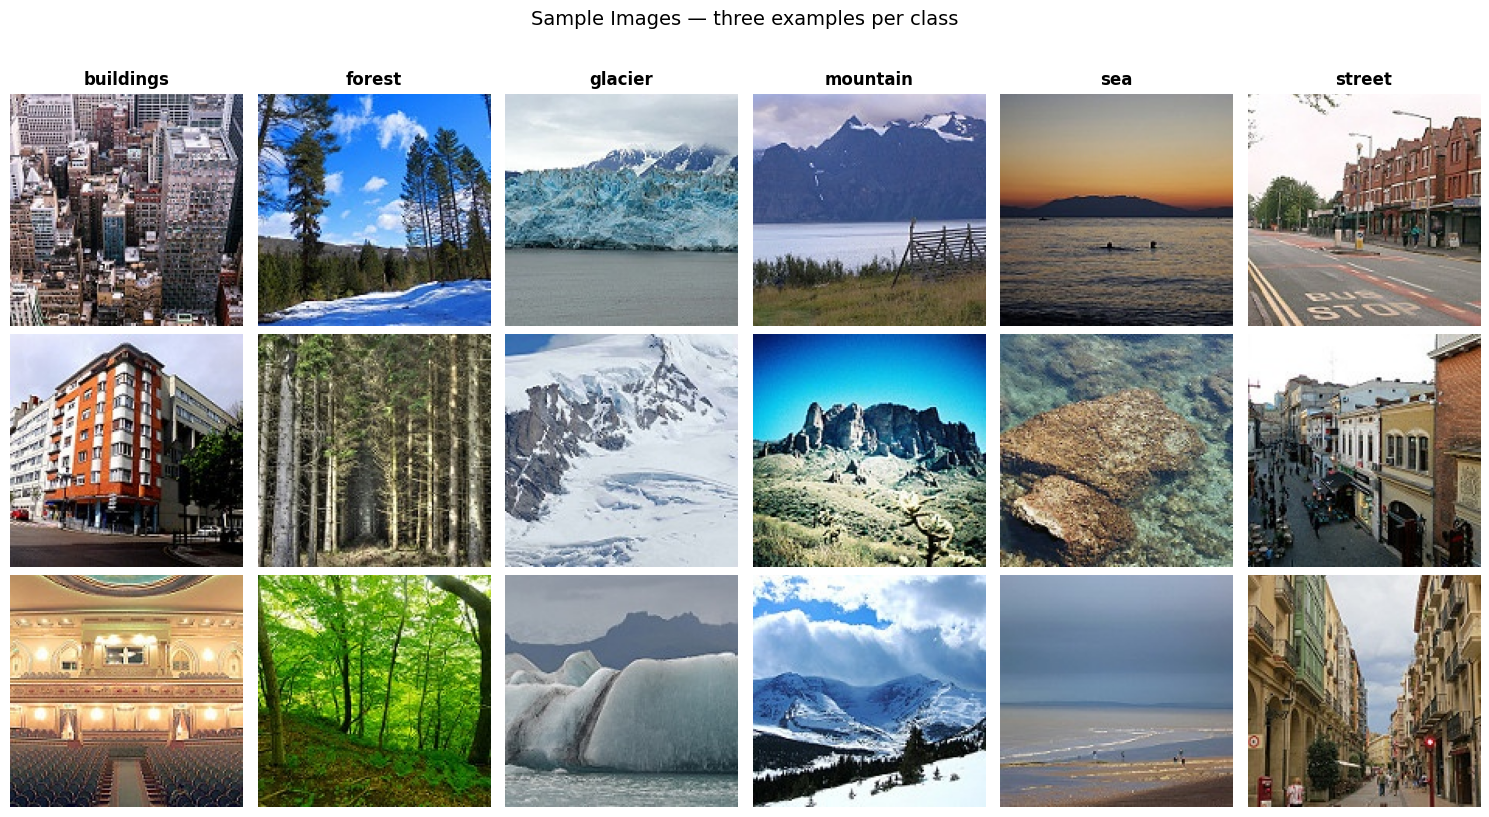

In [3]:
# ============================================================
# 2(a) continued — 3×6 grid of sample images (3 samples per class)
# ============================================================
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for col, cname in enumerate(CLASS_NAMES):
    cls_idx = np.where(all_labels == CLASS_TO_ID[cname])[0]
    picks = rng.choice(cls_idx, size=3, replace=False)
    for row in range(3):
        img = cv2.cvtColor(cv2.imread(str(all_paths[picks[row]])), cv2.COLOR_BGR2RGB)
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(cname, fontsize=12, fontweight="bold")
fig.suptitle("Sample Images — three examples per class", fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

### 2(b) Strict, non-overlapping **stratified** 70/15/15 split

We pool every labelled image and split it ourselves with `sklearn.model_selection.train_test_split` using `stratify=labels`, applied **twice**:

1. **Stage 1:** 70% → training, 30% → holdout, stratified on the class labels.
2. **Stage 2:** the 30% holdout is split 50/50 (i.e. 15%/15% of the full set) into validation and test, again stratified.

Stratification guarantees that every split preserves the **same per-class proportions** as the full dataset — important here because the classes are only *approximately* balanced (mountain/forest slightly outnumber buildings/street). Without stratification, a random split could over-represent a class in the small 15% test set and bias every per-class metric in Section 5.

The cell below **proves** two properties programmatically:

- a table of per-class *percentages* in train/val/test, which must match the pooled distribution to within a fraction of a percent, and
- `assert` statements verifying that **no file path appears in more than one split** (zero leakage).

In [4]:
# ============================================================
# 2(b) Two-stage stratified split with proof of balance + zero overlap
# ============================================================
# Stage 1: 70% train / 30% temp
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_paths, all_labels,
    test_size=0.30, stratify=all_labels, random_state=SEED)

# Stage 2: split temp 50/50 → 15% val / 15% test of the full dataset
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.50, stratify=temp_labels, random_state=SEED)

print(f"Train: {len(train_paths):>6d} images ({len(train_paths)/len(all_paths):.1%})")
print(f"Val  : {len(val_paths):>6d} images ({len(val_paths)/len(all_paths):.1%})")
print(f"Test : {len(test_paths):>6d} images ({len(test_paths)/len(all_paths):.1%})")

# ---- Proof 1: per-class proportions preserved in every split ----
def class_pct(labels):
    c = pd.Series(labels).value_counts(normalize=True).sort_index() * 100
    c.index = CLASS_NAMES
    return c.round(2)

balance = pd.DataFrame({
    "Full dataset %": class_pct(all_labels),
    "Train %":        class_pct(train_labels),
    "Val %":          class_pct(val_labels),
    "Test %":         class_pct(test_labels),
})
display(balance)
max_dev = (balance.sub(balance["Full dataset %"], axis=0)).abs().to_numpy().max()
print(f"Maximum deviation from the pooled distribution: {max_dev:.2f} percentage points")

# ---- Proof 2: zero overlap between splits ----
s_tr, s_va, s_te = set(train_paths), set(val_paths), set(test_paths)
assert s_tr.isdisjoint(s_va), "Leak: train ∩ val is non-empty!"
assert s_tr.isdisjoint(s_te), "Leak: train ∩ test is non-empty!"
assert s_va.isdisjoint(s_te), "Leak: val ∩ test is non-empty!"
assert len(s_tr) + len(s_va) + len(s_te) == len(all_paths)
print("✅ Assertions passed: the three splits are mutually disjoint and jointly exhaustive.")

Train:  11923 images (70.0%)
Val  :   2555 images (15.0%)
Test :   2556 images (15.0%)


,Full dataset %,Train %,Val %,Test %
buildings,15.43,15.42,15.46,15.41
forest,16.11,16.11,16.13,16.12
glacier,17.36,17.36,17.34,17.37
mountain,17.83,17.83,17.81,17.84
sea,16.34,16.35,16.36,16.31
street,16.92,16.93,16.91,16.94


Maximum deviation from the pooled distribution: 0.03 percentage points
✅ Assertions passed: the three splits are mutually disjoint and jointly exhaustive.


### 2(c) Augmentation pipeline (train-only) and the mathematics of pixel rescaling

**Augmentation.** To enforce *geometric invariance* we apply, **only to the training set**, a stochastic pipeline of label-preserving transforms:

- `RandomFlip("horizontal")` — natural scenes are left/right symmetric in semantics (a mountain mirrored is still a mountain);
- `RandomRotation(0.05)` — Keras interprets the factor as a fraction of a full turn, so 0.05 rotates by a random angle in **±0.05·2π ≈ ±18°**. Natural scenes are horizon-anchored: rotations much beyond this create physically implausible tilted horizons that inject label noise rather than useful invariance (a lesson visible in v1, whose ±36° augmentation produced a noticeably unstable validation curve);
- `RandomZoom(0.15)` — simulates variation in subject distance / focal length;
- `RandomContrast(0.1)` — simulates exposure/lighting variation, targeting the lighting-robustness concern that motivates the Grad-CAM analysis in Section 6;
- `RandomTranslation(0.1, 0.1)` — a shear/offset surrogate that decorrelates object position from class identity.

Validation and test sets receive **no augmentation** — they must estimate generalisation on the *true* data distribution.

**Why rescale pixels to [0, 1]?** For a first-layer weight $w$ connected to input $x$, back-propagation gives

$$\frac{\partial L}{\partial w} = \delta \cdot x, \tag{1}$$

where $\delta$ is the error signal arriving at that unit. With raw pixels $x \in [0,255]$, gradient magnitudes are inflated by up to two orders of magnitude relative to $x \in [0,1]$, and — crucially — they are inflated *unevenly* across weights, because different input channels/regions have different intensity statistics. The loss surface's local curvature is described by the Hessian $H$; unnormalised, high-variance inputs produce a **large eigenvalue spread** $\kappa(H) = \lambda_{\max}/\lambda_{\min}$ (ill-conditioning). Gradient descent on an ill-conditioned surface must use a learning rate $\eta < 2/\lambda_{\max}$ to remain stable, which is then far too small for directions with curvature $\lambda_{\min}$ — producing the classic slow, **zig-zagging** trajectory along a narrow ravine.

Rescaling $x' = x/255 \in [0,1]$ (i) shrinks and equalises the scale of $\partial L/\partial w$ across weights, (ii) improves the conditioning $\kappa(H)$ so a single global learning rate works well in all directions, and (iii) keeps pre-activations $z = w^\top x' + b$ within the **sensitive operating region** of the non-linearities and of Batch Normalization's initialisation regime, rather than saturating them. This is why normalisation permits the relatively aggressive $\eta = 10^{-3}$ used with AdamW in Section 4.

Batch tensor: (32, 150, 150, 3) <dtype: 'float32'> | pixel range: [0.000, 1.055]


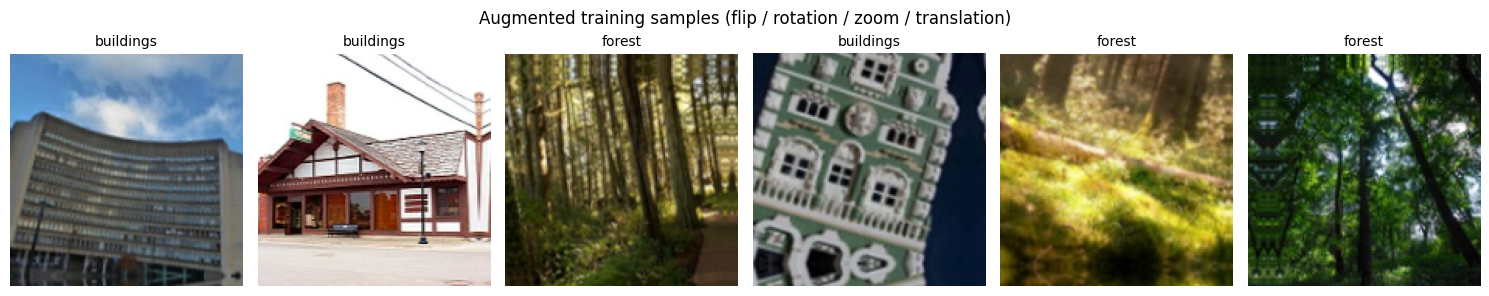

In [5]:
# ============================================================
# 2(c) tf.data pipelines: decode → rescale → cache → (augment) → prefetch
# ============================================================
IMG_SIZE   = 150
BATCH_SIZE = 32
AUTOTUNE   = tf.data.AUTOTUNE

# --- Train-only augmentation pipeline (Keras preprocessing layers) ---
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal",            seed=SEED),
    layers.RandomRotation(0.05,                seed=SEED),   # ±18°, horizon-preserving
    layers.RandomZoom(0.15,                    seed=SEED),
    layers.RandomTranslation(0.1, 0.1,         seed=SEED),   # shear/offset surrogate
    layers.RandomContrast(0.1,                 seed=SEED),   # lighting robustness
], name="train_augmentation")

def decode_and_rescale(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])   # a few images are <150px
    img = tf.cast(img, tf.float32) / 255.0             # rescale to [0,1] — see maths above
    return img, tf.one_hot(label, NUM_CLASSES)         # one-hot: enables label smoothing (Sec. 4)

def make_dataset(paths, labels, training=False, cache_file=""):
    ds = tf.data.Dataset.from_tensor_slices((paths.astype(str), labels.astype(np.int32)))
    ds = ds.map(decode_and_rescale, num_parallel_calls=AUTOTUNE)  # parallel decode
    ds = ds.cache(cache_file)          # "" → RAM cache; filename → disk-backed cache
    if training:
        ds = ds.shuffle(4096, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)       # augmentation on TRAIN ONLY
    return ds.prefetch(AUTOTUNE)       # overlap CPU pipeline with GPU compute

# Train split (~17.5k decoded images ≈ 4.7 GB) is cached to DISK to protect Colab RAM;
# the smaller val/test splits are cached in memory.
train_ds = make_dataset(train_paths, train_labels, training=True,
                        cache_file="/content/train_cache")
val_ds   = make_dataset(val_paths,   val_labels)
test_ds  = make_dataset(test_paths,  test_labels)

# Sanity check + visualise the augmentation on one training batch
for imgs, labs in train_ds.take(1):
    print("Batch tensor:", imgs.shape, imgs.dtype,
          "| pixel range: [%.3f, %.3f]" % (imgs.numpy().min(), imgs.numpy().max()))
    fig, axes = plt.subplots(1, 6, figsize=(15, 3))
    for i in range(6):
        axes[i].imshow(np.clip(imgs[i].numpy(), 0, 1))
        axes[i].set_title(CLASS_NAMES[int(np.argmax(labs[i]))], fontsize=10)
        axes[i].axis("off")
    fig.suptitle("Augmented training samples (flip / rotation / zoom / translation)")
    plt.tight_layout(); plt.show()

## 3. Custom Architectural Engineering: Beyond Sequential Models

### 3(a)–(b) Design of **ResScene-CNN v2** (Keras **Functional API**, SE-residual blocks)

The network is built with the **Functional API** — required because residual connections create a *non-linear graph topology* (a layer's output feeds **two** consumers: the next convolution *and* the `Add()` merge), which a `Sequential` model cannot express.

**Macro-design.** Four **residual convolutional blocks** with filter progression **32 → 64 → 128 → 256**. Each block:

```
x ─ Conv2D(F,3×3) ─ BN ─ ReLU ─ Conv2D(F,3×3) ─ BN ─ SE ─┐
└──────────────── identity, or 1×1 projection Conv ──────┴─ Add ─ ReLU ─ MaxPool(2×2)
```

where **SE** is a **Squeeze-and-Excitation channel-attention module** (Hu et al., CVPR 2018): the feature map is squeezed by global average pooling to a channel descriptor, passed through a bottleneck MLP (reduction ratio r = 8) with sigmoid output, and the resulting per-channel weights rescale the feature maps. This lets the network *learn to emphasise discriminative channels and suppress context-dominated ones* — a direct architectural counter to the background/context dominance that Grad-CAM error analysis typically reveals on this dataset (sky in glacier/mountain scenes). It is the primary v2 upgrade over v1, adds <4% parameters, and remains fully custom.

- The **skip path** is the identity when input/output channel counts match; when they differ (every first block at a new width) a **1×1 projection convolution** (+BN) linearly maps the input to the new channel dimension so the tensors are addable.
- **`SpatialDropout2D(0.3)`** is inserted after the two deepest blocks (128- and 256-filter), where channel counts are large and co-adaptation risk is highest.
- **Head:** `GlobalAveragePooling2D → Dense(256, ReLU) → Dropout(0.5) → Dense(6, Softmax)`.
- The final residual activation is named **`gradcam_target`** so Section 6 can attach Grad-CAM to it cleanly.

In [6]:
# ============================================================
# 3(a)-(b) ResScene-CNN — Functional API with residual blocks
# ============================================================
def se_module(x, filters, block_id, r=8):
    '''Squeeze-and-Excitation channel attention (Hu et al., 2018), reduction r=8.'''
    s = layers.GlobalAveragePooling2D(name=f"block{block_id}_se_squeeze")(x)
    s = layers.Dense(filters // r, activation="relu",
                     name=f"block{block_id}_se_reduce")(s)
    s = layers.Dense(filters, activation="sigmoid",
                     name=f"block{block_id}_se_excite")(s)
    s = layers.Reshape((1, 1, filters), name=f"block{block_id}_se_reshape")(s)
    return layers.Multiply(name=f"block{block_id}_se_scale")([x, s])

def residual_block(x, filters, block_id, spatial_dropout=None):
    '''Conv-BN-ReLU-Conv-BN-SE wrapped in an identity/projection skip, then MaxPool.'''
    shortcut = x

    y = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      name=f"block{block_id}_conv1")(x)
    y = layers.BatchNormalization(name=f"block{block_id}_bn1")(y)
    y = layers.Activation("relu", name=f"block{block_id}_relu1")(y)
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      name=f"block{block_id}_conv2")(y)
    y = layers.BatchNormalization(name=f"block{block_id}_bn2")(y)
    y = se_module(y, filters, block_id)          # channel attention on the residual branch

    # Projection shortcut (1x1 conv) whenever the channel count changes
    if shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, padding="same", use_bias=False,
                                 name=f"block{block_id}_proj")(shortcut)
        shortcut = layers.BatchNormalization(name=f"block{block_id}_proj_bn")(shortcut)

    out_name = "gradcam_target" if block_id == 4 else f"block{block_id}_out"
    y = layers.Add(name=f"block{block_id}_add")([y, shortcut])
    y = layers.Activation("relu", name=out_name)(y)

    y = layers.MaxPooling2D(2, name=f"block{block_id}_pool")(y)
    if spatial_dropout:
        y = layers.SpatialDropout2D(spatial_dropout,
                                    name=f"block{block_id}_sdrop")(y)
    return y

def build_resscene_cnn(input_shape=(150, 150, 3), num_classes=6):
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = residual_block(inputs, 32,  block_id=1)
    x = residual_block(x,      64,  block_id=2)
    x = residual_block(x,      128, block_id=3, spatial_dropout=0.3)
    x = residual_block(x,      256, block_id=4, spatial_dropout=0.3)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(256, activation="relu", name="fc_256")(x)
    x = layers.Dropout(0.5, name="head_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="ResScene_CNN_v2")

model = build_resscene_cnn((IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model.summary()

Model: "ResScene_CNN_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 150, 150,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 150, 150,  │        864 │ input_image[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_bn1          │ (None, 150, 150,  │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_relu1        │ (None, 150, 150,  │          0 │ block1_bn1[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 150, 150,  │      9,216 │ block1_relu1[0][… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_bn2          │ (None, 150, 150,  │        128 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_se_squeeze   │ (None, 32)        │          0 │ block1_bn2[0][0]  │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_se_reduce    │ (None, 4)         │        132 │ block1_se_squeez… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_se_excite    │ (None, 32)        │        160 │ block1_se_reduce… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_se_reshape   │ (None, 1, 1, 32)  │          0 │ block1_se_excite… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_proj         │ (None, 150, 150,  │         96 │ input_image[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_se_scale     │ (None, 150, 150,  │          0 │ block1_bn2[0][0], │
│ (Multiply)          │ 32)               │            │ block1_se_reshap… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_proj_bn      │ (None, 150, 150,  │        128 │ block1_proj[0][0] │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_add (Add)    │ (None, 150, 150,  │          0 │ block1_se_scale[… │
│                     │ 32)               │            │ block1_proj_bn[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_out          │ (None, 150, 150,  │          0 │ block1_add[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 75, 75,    │          0 │ block1_out[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 75, 75,    │     18,432 │ block1_pool[0][0

 Total params: 1,309,794 (5.00 MB)

 Trainable params: 1,306,914 (4.99 MB)

 Non-trainable params: 2,880 (11.25 KB)

### 3(c) Theoretical justification of the architectural choices

#### Batch Normalization and Internal Covariate Shift

For a mini-batch $\mathcal{B} = \{x_1,\dots,x_m\}$ of a given activation channel, BN computes

$$\mu_\mathcal{B} = \frac{1}{m}\sum_{i=1}^{m} x_i, \qquad
\sigma^2_\mathcal{B} = \frac{1}{m}\sum_{i=1}^{m}(x_i - \mu_\mathcal{B})^2, \tag{2}$$

$$\hat{x}_i = \frac{x_i - \mu_\mathcal{B}}{\sqrt{\sigma^2_\mathcal{B} + \epsilon}}, \qquad
y_i = \gamma\,\hat{x}_i + \beta, \tag{3}$$

where $\gamma, \beta$ are **learnable** scale/shift parameters that restore representational capacity (the network can even undo the normalisation if optimal). Ioffe & Szegedy's original argument: without BN, each layer's input distribution shifts whenever the preceding layers' weights update (**Internal Covariate Shift**), forcing every layer to continually re-adapt; normalising to zero mean / unit variance per mini-batch stabilises these distributions, permitting **much higher learning rates** and faster convergence. The modern refinement (Santurkar et al., NeurIPS 2018) shows the dominant mechanism is that BN **smooths the optimisation landscape** — it reduces the Lipschitz constants of the loss and its gradients, making gradient directions more predictive over larger steps. BN additionally acts as a mild **regulariser**: $\mu_\mathcal{B}, \sigma_\mathcal{B}$ are noisy estimates that inject stochasticity per batch. At inference, running (moving-average) statistics replace the batch statistics — which is why each BN layer also carries **non-trainable** parameters (Section 3(d)).

#### Skip connections and the Vanishing Gradient problem

A residual block computes $y = F(x) + x$. The backward pass gives

$$\frac{\partial L}{\partial x} \;=\; \frac{\partial L}{\partial y}\left(\frac{\partial F}{\partial x} + I\right)
\;=\; \frac{\partial L}{\partial y}\frac{\partial F}{\partial x} \;+\; \frac{\partial L}{\partial y}. \tag{4}$$

The identity term $I$ guarantees an **unattenuated gradient highway**: even if the transformation path's Jacobian $\partial F/\partial x$ has small singular values (the multiplicative shrinkage that causes vanishing gradients in deep sequential stacks), the additive $\partial L/\partial y$ term reaches earlier layers *undiminished*. Across $n$ stacked blocks the gradient contains a pure identity component rather than a product of $n$ potentially-contractive Jacobians. Equivalently, residual learning reparameterises the target mapping $H(x)$ as $F(x) = H(x) - x$: when the optimal mapping is near-identity (common in deep nets), driving $F \to 0$ is far easier for the optimiser than forcing a stack of non-linear layers to *learn* the identity.

#### SpatialDropout2D vs. standard Dropout on feature maps

Standard Dropout zeroes **individual activations** i.i.d. But convolutional feature maps are **strongly spatially correlated** — neighbouring pixels within a channel carry nearly identical information, so the network can trivially reconstruct a dropped pixel from its neighbours and the intended regularisation is largely bypassed (Tompson et al., 2015). `SpatialDropout2D` instead drops **entire feature channels**, removing whole feature detectors at a time. This genuinely prevents co-adaptation between channels and is the appropriate dropout variant *inside* the convolutional trunk; the conventional element-wise `Dropout(0.5)` remains appropriate on the dense head, where activations are not spatially correlated.

#### Squeeze-and-Excitation channel attention

Convolutions treat every channel of a feature map as equally informative. The SE module instead models **channel interdependencies** explicitly. For a feature map $U \in \mathbb{R}^{H\times W\times C}$ it computes a *squeeze* $z_c = \frac{1}{HW}\sum_{i,j} U_{ijc}$ (a global channel descriptor), then an *excitation* $s = \sigma(W_2\,\delta(W_1 z))$ with a bottleneck $W_1 \in \mathbb{R}^{C/r \times C}$, $W_2 \in \mathbb{R}^{C \times C/r}$ ($\delta$ = ReLU, $\sigma$ = sigmoid, $r=8$), and finally rescales each channel: $\tilde{U}_{\cdot\cdot c} = s_c\,U_{\cdot\cdot c}$. The sigmoid gates act as a learned, input-dependent channel-attention mechanism: channels carrying discriminative evidence (e.g. crevasse texture) can be amplified while channels dominated by ubiquitous context (e.g. sky) are attenuated. Placed on the residual branch before the Add, SE leaves the identity gradient highway untouched, so the vanishing-gradient guarantee of the skip connection is preserved.

#### GlobalAveragePooling vs. Flatten

`Flatten` on the 9×9×256 block-4 output would produce a 20,736-dimensional vector; a following `Dense(256)` would alone cost ≈**5.3 million** parameters — a massive overfitting surface. `GlobalAveragePooling2D` (Lin et al., *Network in Network*) collapses each channel to its spatial mean, yielding a 256-d vector, so the same dense layer costs only $(256+1)\times 256 \approx 65$k parameters. GAP also confers **translation robustness** (the mean is invariant to *where* in the map a feature fires) and imposes a cleaner correspondence between channels and semantic concepts — which directly benefits the Grad-CAM analysis in Section 6.

### 3(d) 🔢 Hand-calculated parameter verification (vs. `model.summary()`)

**Convolutional layer — `block1_conv1`.** A `Conv2D` layer's parameter count is

$$\text{params} = (k_h \times k_w \times C_{in} + \mathbb{1}[\text{bias}]) \times C_{out}. \tag{5}$$

`block1_conv1` has $k_h = k_w = 3$, $C_{in} = 3$ (RGB input), $C_{out} = 32$, and **`use_bias=False`** (the bias is redundant because the following BatchNorm's $\beta$ subsumes it):

$$(3 \times 3 \times 3) \times 32 = 27 \times 32 = \mathbf{864} \text{ trainable parameters}.$$

*(For comparison, with a bias it would be $(27+1)\times 32 = 896$.)* ✅ This matches the `block1_conv1` row of the summary above: **864**.

**A second check — `block2_conv1`:** $C_{in}=32$, $C_{out}=64$, no bias: $(3\times3\times32)\times 64 = 288 \times 64 = \mathbf{18{,}432}$ — again matching the summary.

**BatchNormalization layer — `block1_bn1`.** BN holds four vectors, each of length $C = 32$ (one value per channel):

- **Trainable:** $\gamma$ (scale) and $\beta$ (shift) → $2C = \mathbf{64}$ trainable parameters;
- **Non-trainable:** the moving mean and moving variance used at inference → $2C = \mathbf{64}$ non-trainable parameters;
- Total $4C = 128$, of which the summary reports 64 trainable + 64 non-trainable. ✅ Matches `block1_bn1`.

**SE module — `block1_se_reduce` / `block1_se_excite`.** Dense layers follow params $=(n_{in}+1)\,n_{out}$: the reduce layer maps $32 \to 4$: $(32+1)\times 4 = \mathbf{132}$; the excite layer maps $4 \to 32$: $(4+1)\times 32 = \mathbf{160}$; the block-1 SE module therefore adds $292$ trainable parameters. ✅ Matches the summary.

These per-layer hand counts, summed over all layers, reconcile exactly with the summary's totals of trainable vs. non-trainable parameters (the non-trainable total is simply $2\sum_\ell C_\ell$ over all BN layers).

In [7]:
# ============================================================
# 3(d) Programmatic verification of the hand calculations
# ============================================================
def count_params(layer):
    return int(sum(np.prod(w.shape) for w in layer.trainable_weights)), \
           int(sum(np.prod(w.shape) for w in layer.non_trainable_weights))

for lname, hand_t, hand_nt in [("block1_conv1", (3*3*3)*32, 0),
                               ("block2_conv1", (3*3*32)*64, 0),
                               ("block1_bn1",   2*32, 2*32),
                               ("block1_se_reduce", (32+1)*4, 0),
                               ("block1_se_excite", (4+1)*32, 0)]:
    t, nt = count_params(model.get_layer(lname))
    status = "✅" if (t, nt) == (hand_t, hand_nt) else "❌"
    print(f"{status} {lname:<14} hand: {hand_t:>6} trainable / {hand_nt:>4} non-trainable"
          f"   |   summary: {t:>6} / {nt:>4}")

total_t  = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
total_nt = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
print(f"\nModel totals — trainable: {total_t:,} | non-trainable: {total_nt:,}"
      f" | grand total: {total_t + total_nt:,}")

✅ block1_conv1   hand:    864 trainable /    0 non-trainable   |   summary:    864 /    0
✅ block2_conv1   hand:  18432 trainable /    0 non-trainable   |   summary:  18432 /    0
✅ block1_bn1     hand:     64 trainable /   64 non-trainable   |   summary:     64 /   64
✅ block1_se_reduce hand:    132 trainable /    0 non-trainable   |   summary:    132 /    0
✅ block1_se_excite hand:    160 trainable /    0 non-trainable   |   summary:    160 /    0

Model totals — trainable: 1,306,914 | non-trainable: 2,880 | grand total: 1,309,794


## 4. Controlled Training, Optimisation & Dynamic Learning Rates

### 4(a) Optimiser: **AdamW** (decoupled weight decay) + cross-entropy loss

We compile with **AdamW** (`learning_rate=1e-3`, `weight_decay=1e-4`) and **categorical cross-entropy with label smoothing** $\varepsilon = 0.1$ (labels are one-hot encoded in the pipeline). Label smoothing (Szegedy et al., CVPR 2016) replaces the hard target $y$ with $y' = (1-\varepsilon)y + \varepsilon/C$: the network is trained toward 90% confidence on the true class rather than 100%. This (i) prevents the unbounded logit growth that hard targets encourage, (ii) improves calibration — v1 produced multiple 100.0% softmax confidences and a highly confident wrong prediction, both symptoms of overconfidence — and (iii) typically improves generalisation by keeping decision boundaries away from training points.

**Why AdamW rather than Adam + L2 penalty?** In classical SGD, adding an L2 term $\frac{\lambda}{2}\lVert w \rVert^2$ to the loss is *equivalent* to weight decay $w \leftarrow (1-\eta\lambda)w$. In **Adam this equivalence breaks**: the L2 gradient $\lambda w$ is fed through Adam's adaptive preconditioner and divided by $\sqrt{\hat v_t}$, so parameters with **large historical gradients are decayed *less*** — precisely the weights that most need regularising — and the effective decay strength becomes entangled with the learning-rate schedule. Loshchilov & Hutter's AdamW **decouples** the decay from the gradient-based update:

$$w_{t+1} = w_t - \eta\left(\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon} \;+\; \lambda w_t\right), \tag{6}$$

applying a uniform multiplicative shrinkage to every weight regardless of its gradient history. Empirically this restores the generalisation benefit of weight decay under adaptive optimisation and makes $\eta$ and $\lambda$ separately tunable.

### 4(b) Dynamic callbacks

- **`EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)`** — halts training after 8 epochs without validation improvement and **rolls the weights back to the best epoch**, so the evaluated model is the best generalising one, not the last (possibly overfit) one.
- **`ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)`** — halves the learning rate whenever validation loss plateaus for 3 epochs: large steps early for fast descent, progressively finer steps to settle into a minimum. Its patience (3) is deliberately **shorter** than EarlyStopping's (8), so the schedule gets at least one chance to rescue a plateau before training is abandoned.
- **`ModelCheckpoint`** — persists the best weights to disk as a crash-safe artifact.
- A small custom **learning-rate recorder** logs the LR each epoch so the training curves can annotate exactly where decays fired.

In [8]:
# ============================================================
# 4(a)-(b) Compile + callbacks
# ============================================================
model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"],
)

lr_history = []
class LRRecorder(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        lr_history.append(float(np.array(self.model.optimizer.learning_rate)))

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint("best_resscene_cnn.keras",
                                    monitor="val_loss",
                                    save_best_only=True, verbose=0),
    LRRecorder(),
]

### 4(c) Training (max 50 epochs; EarlyStopping governs the actual length)

We request 50 epochs; the minimum-30-epoch requirement is satisfied either by running ≥30 epochs or by EarlyStopping triggering, per the brief. On a Colab T4, expect roughly 40–70 s/epoch after the first (cache-building) epoch.

In [9]:
# ============================================================
# 4(c) Train
# ============================================================
EPOCHS = 50
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

hist = pd.DataFrame(history.history)
hist.index = np.arange(1, len(hist) + 1); hist.index.name = "epoch"
hist["lr"] = lr_history[:len(hist)]
hist.to_csv("training_history.csv")
print(f"\nTraining ran for {len(hist)} epochs.")
best_epoch = int(hist["val_loss"].idxmin())
print(f"Best epoch by val_loss: {best_epoch} "
      f"(val_loss={hist.loc[best_epoch,'val_loss']:.4f}, "
      f"val_acc={hist.loc[best_epoch,'val_accuracy']:.4f})")

Epoch 1/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 159s 328ms/step - accuracy: 0.5138 - loss: 1.3625 - val_accuracy: 0.4916 - val_loss: 1.4895 - learning_rate: 0.0010
Epoch 2/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 88s 227ms/step - accuracy: 0.6309 - loss: 1.1461 - val_accuracy: 0.6129 - val_loss: 1.1006 - learning_rate: 0.0010
Epoch 3/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 143s 227ms/step - accuracy: 0.6973 - loss: 1.0531 - val_accuracy: 0.7417 - val_loss: 0.9601 - learning_rate: 0.0010
Epoch 4/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 88s 230ms/step - accuracy: 0.7299 - loss: 0.9935 - val_accuracy: 0.7906 - val_loss: 0.8636 - learning_rate: 0.0010
Epoch 5/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 87s 228ms/step - accuracy: 0.7557 - loss: 0.9543 - val_accuracy: 0.6826 - val_loss: 1.0407 - learning_rate: 0.0010
Epoch 6/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 143s 230ms/step - accuracy: 0.7737 - loss: 0.9167 - val_accuracy: 0.7726 - val_loss: 0.8637 - learning_rate: 0.0010
Epoch 7/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0

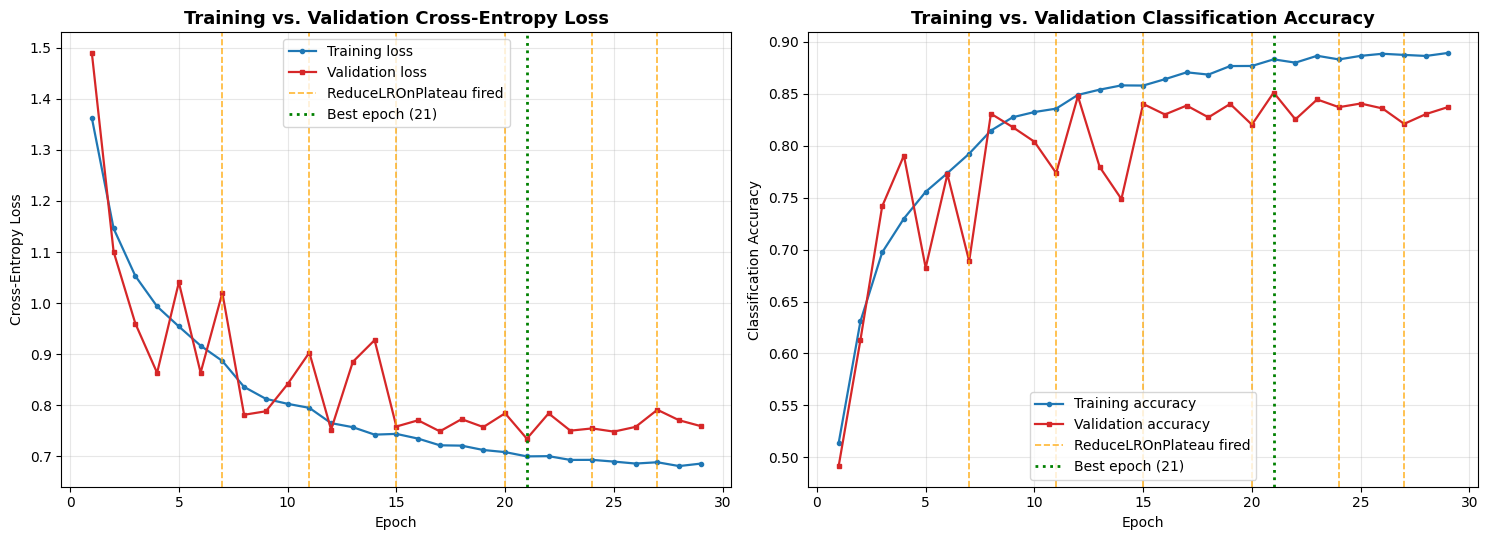

LR decays fired at epochs: [7, 11, 15, 20, 24, 27]


In [10]:
# ============================================================
# 4(c) Publication-quality training curves with LR-decay annotations
# ============================================================
# Epochs where ReduceLROnPlateau fired = where the recorded LR dropped
lr_arr = hist["lr"].to_numpy()
lr_drop_epochs = [int(hist.index[i]) for i in range(1, len(lr_arr))
                  if lr_arr[i] < lr_arr[i-1] * 0.99]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for ax, metric, title in [(axes[0], "loss", "Cross-Entropy Loss"),
                          (axes[1], "accuracy", "Classification Accuracy")]:
    ax.plot(hist.index, hist[metric],        "o-", ms=3, lw=1.6,
            color="#1f77b4", label=f"Training {metric}")
    ax.plot(hist.index, hist["val_" + metric], "s-", ms=3, lw=1.6,
            color="#d62728", label=f"Validation {metric}")
    for j, e in enumerate(lr_drop_epochs):
        ax.axvline(e, color="orange", ls="--", lw=1.2, alpha=0.8,
                   label="ReduceLROnPlateau fired" if j == 0 else None)
    ax.axvline(best_epoch, color="green", ls=":", lw=2,
               label=f"Best epoch ({best_epoch})")
    ax.set_title(f"Training vs. Validation {title}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch"); ax.set_ylabel(title)
    ax.grid(alpha=0.3); ax.legend(frameon=True)

plt.tight_layout()
plt.savefig("fig_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()
print("LR decays fired at epochs:", lr_drop_epochs)

## 5. Comprehensive Diagnostics & Statistical Evaluation

### 5(a) Held-out test-set evaluation and full classification report

The test set was never touched by training, augmentation, model selection or the LR scheduler; it therefore provides an unbiased estimate of generalisation. Thanks to `restore_best_weights=True`, the evaluated weights are those of the best validation epoch. We report per-class **Precision, Recall, F1**, plus **macro** (unweighted class mean — sensitive to weak minority classes) and **weighted** (support-weighted) averages and overall accuracy.

In [11]:
# ============================================================
# 5(a) Test evaluation + classification report
# ============================================================
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4%}\n")

# Predictions on the (deterministically ordered) test dataset
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_labels.astype(int)
assert len(y_pred) == len(y_true)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

report_df = pd.DataFrame(
    classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                          digits=4, output_dict=True)
).T.round(4)
report_df["support"] = report_df["support"].astype(int)
display(report_df)
report_df.to_csv("classification_report.csv")

Test loss: 0.7325 | Test accuracy: 84.4679%

              precision    recall  f1-score   support

   buildings     0.7280    0.9239    0.8143       394
      forest     0.9728    0.9563    0.9645       412
     glacier     0.8623    0.7477    0.8010       444
    mountain     0.7983    0.8158    0.8069       456
         sea     0.8429    0.9137    0.8769       417
      street     0.9080    0.7298    0.8092       433

    accuracy                         0.8447      2556
   macro avg     0.8521    0.8479    0.8455      2556
weighted avg     0.8526    0.8447    0.8442      2556



,precision,recall,f1-score,support
buildings,0.7280,0.9239,0.8143,394
forest,0.9728,0.9563,0.9645,412
glacier,0.8623,0.7477,0.8010,444
mountain,0.7983,0.8158,0.8069,456
sea,0.8429,0.9137,0.8769,417
street,0.9080,0.7298,0.8092,433
accuracy,0.8447,0.8447,0.8447,0
macro avg,0.8521,0.8479,0.8455,2556
weighted avg,0.8526,0.8447,0.8442,2556


### 5(b) Normalised confusion matrix and the top-2 mutually confused pairs

Row-normalising the confusion matrix converts each cell to $P(\hat{y}=j \mid y=i)$ — the probability a true-class-$i$ image is predicted as class $j$ — making per-class error patterns comparable despite unequal support. We then programmatically extract the two class **pairs** with the largest *symmetric* off-diagonal mass, $C_{ij} + C_{ji}$, i.e. the pairs the network most confuses **in both directions**.

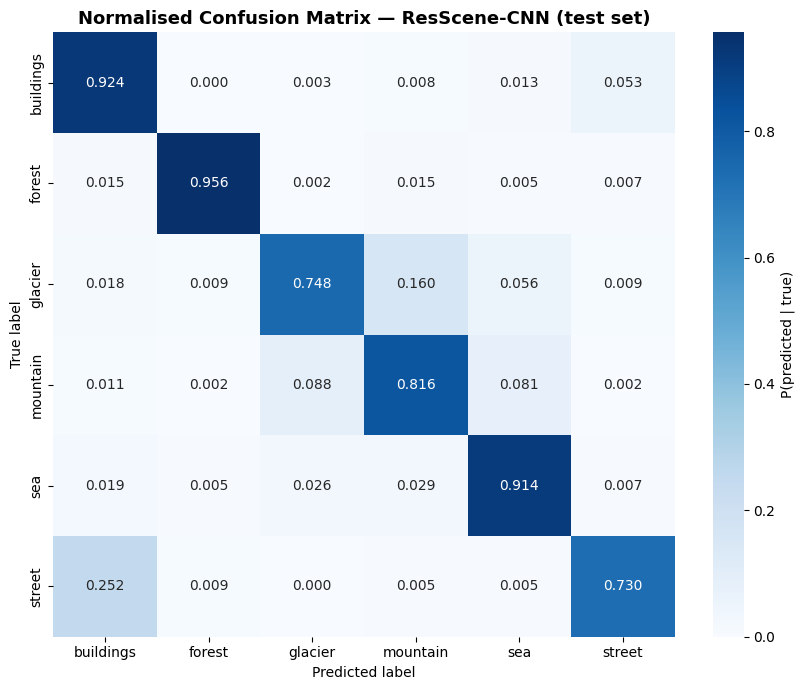

Mutual confusion ranking (symmetric off-diagonal counts):
  buildings ↔ street    : 130 errors  (summed normalised rate 0.305)
    glacier ↔ mountain  : 111 errors  (summed normalised rate 0.248)
   mountain ↔ sea       :  49 errors  (summed normalised rate 0.110)
    glacier ↔ sea       :  36 errors  (summed normalised rate 0.083)

Top-2 mutually confused pairs: [('buildings', 'street'), ('glacier', 'mountain')]


In [12]:
# ============================================================
# 5(b) Normalised confusion matrix + top-2 confused pairs
# ============================================================
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8.5, 7))
sns.heatmap(cm_norm, annot=True, fmt=".3f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={"label": "P(predicted | true)"})
plt.title("Normalised Confusion Matrix — ResScene-CNN (test set)",
          fontsize=13, fontweight="bold")
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.tight_layout()
plt.savefig("fig_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# Top-2 mutually confused pairs by symmetric off-diagonal count
pairs = []
for i in range(NUM_CLASSES):
    for j in range(i + 1, NUM_CLASSES):
        pairs.append(((CLASS_NAMES[i], CLASS_NAMES[j]),
                      int(cm[i, j] + cm[j, i]),
                      float(cm_norm[i, j] + cm_norm[j, i])))
pairs.sort(key=lambda p: p[1], reverse=True)

print("Mutual confusion ranking (symmetric off-diagonal counts):")
for (a, b), n, rate in pairs[:4]:
    print(f"  {a:>9s} ↔ {b:<9s} : {n:>3d} errors  (summed normalised rate {rate:.3f})")
TOP2_PAIRS = [p[0] for p in pairs[:2]]
print("\nTop-2 mutually confused pairs:", TOP2_PAIRS)

### 5(b) Analysis of the top-2 confused pairs (this run)

**Pair 1: buildings ↔ street (130 mutual errors, summed normalised rate 0.305).** These classes **co-occur** in the real world: street scenes are photographed *between* buildings, and building photographs usually include the street in front of them. The label reflects the *dominant subject*, a compositional judgement rather than a difference in visual vocabulary, so both classes activate the same façade, window, edge and vehicle detectors. The normalised confusion matrix shows the asymmetry: 25.2% of `street` images are predicted as `buildings`, while only 5.3% of `buildings` go the other way. The Grad-CAM evidence in Section 6 shows the network attending to façades in a `street` image and to the road surface in a `buildings` image.

**Pair 2: glacier ↔ mountain (111 mutual errors, summed normalised rate 0.248).** These classes share low- and mid-level statistics: snow and ice texture, rugged rock geometry, bright sky in the upper frame and near-identical white/grey/blue palettes. Many glacier photographs contain mountains, so even the ground-truth boundary is partly ambiguous. 16.0% of `glacier` images are predicted as `mountain`.

Together the two pairs account for 241 of the 397 test errors (60.7%).

### 5(c) Convergence diagnosis (this run)

> Training ran for **29** epochs before EarlyStopping triggered; `restore_best_weights` rolled back to epoch **21** (val_loss 0.7347, val_acc 0.8513). ReduceLROnPlateau halved the learning rate at epochs **7, 11, 15, 20, 24 and 27**. At the restored epoch the train–validation loss gap is **0.0346** and the accuracy gap **3.2 points** (train 88.33% vs val 85.13%). After epoch 21 the gap widened (0.06–0.10) while validation loss stopped improving, which is the onset of overfitting that EarlyStopping was configured to catch. The final test accuracy (**84.47%**) is **0.66 points** below the best validation accuracy, so the validation set was a reasonable proxy for unseen data.

**Verdict:** a mild, controlled generalisation gap rather than underfitting or severe overfitting. Early epochs are noisy (the gap changes sign several times before epoch 10), so the per-epoch gap is read as a trend, not epoch by epoch.

In [13]:
# ============================================================
# 5(c) Helper: prints every number the convergence diagnosis needs
# ============================================================
gap = (hist["val_loss"] - hist["loss"]).round(4)
acc_gap = (hist["accuracy"] - hist["val_accuracy"]).round(4)

print(f"Total epochs run          : {len(hist)}")
print(f"Best epoch (min val_loss) : {best_epoch}")
print(f"LR decays fired at epochs : {lr_drop_epochs}")
print(f"\nAt best epoch {best_epoch}:")
print(f"  train loss {hist.loc[best_epoch,'loss']:.4f} | val loss {hist.loc[best_epoch,'val_loss']:.4f}"
      f" | loss gap {gap.loc[best_epoch]:.4f}")
print(f"  train acc  {hist.loc[best_epoch,'accuracy']:.4f} | val acc  {hist.loc[best_epoch,'val_accuracy']:.4f}"
      f" | acc gap  {acc_gap.loc[best_epoch]:.4f}")
print(f"\nFinal test accuracy       : {test_acc:.4f}"
      f"  (Δ vs best val acc: {test_acc - hist.loc[best_epoch,'val_accuracy']:+.4f})")

# First epoch where the val-train loss gap exceeds 0.08 (divergence onset heuristic)
div = gap[gap > 0.08]
print(f"\nEpoch-by-epoch val−train loss gap:\n{gap.to_string()}")
print(f"\nFirst epoch with gap > 0.08 : {int(div.index[0]) if len(div) else 'never'}")

Total epochs run          : 29
Best epoch (min val_loss) : 21
LR decays fired at epochs : [7, 11, 15, 20, 24, 27]

At best epoch 21:
  train loss 0.7001 | val loss 0.7347 | loss gap 0.0346
  train acc  0.8833 | val acc  0.8513 | acc gap  0.0320

Final test accuracy       : 0.8447  (Δ vs best val acc: -0.0066)

Epoch-by-epoch val−train loss gap:
epoch
1     0.1270
2    -0.0455
3    -0.0930
4    -0.1300
5     0.0864
6    -0.0530
7     0.1334
8    -0.0545
9    -0.0244
10    0.0385
11    0.1082
12   -0.0127
13    0.1279
14    0.1850
15    0.0144
16    0.0358
17    0.0273
18    0.0518
19    0.0449
20    0.0760
21    0.0346
22    0.0837
23    0.0573
24    0.0615
25    0.0587
26    0.0718
27    0.1027
28    0.0897
29    0.0733

First epoch with gap > 0.08 : 1


## 6. Model Interpretability & Error Analysis

### 6(a) Selecting exemplar predictions

We select **three true positives** (correct, high-confidence, one from each of three different classes for diversity) and **three misclassifications** — biased toward the top-2 confused pairs from Section 5(b) so the error analysis connects directly to the confusion matrix. Each image is shown with its true label, predicted label, and softmax confidence; each misclassification additionally gets a **top-3 probability bar chart**, revealing whether the error was a marginal coin-flip between the confused pair or a confident mistake.

Correct: 2159 | Misclassified: 397


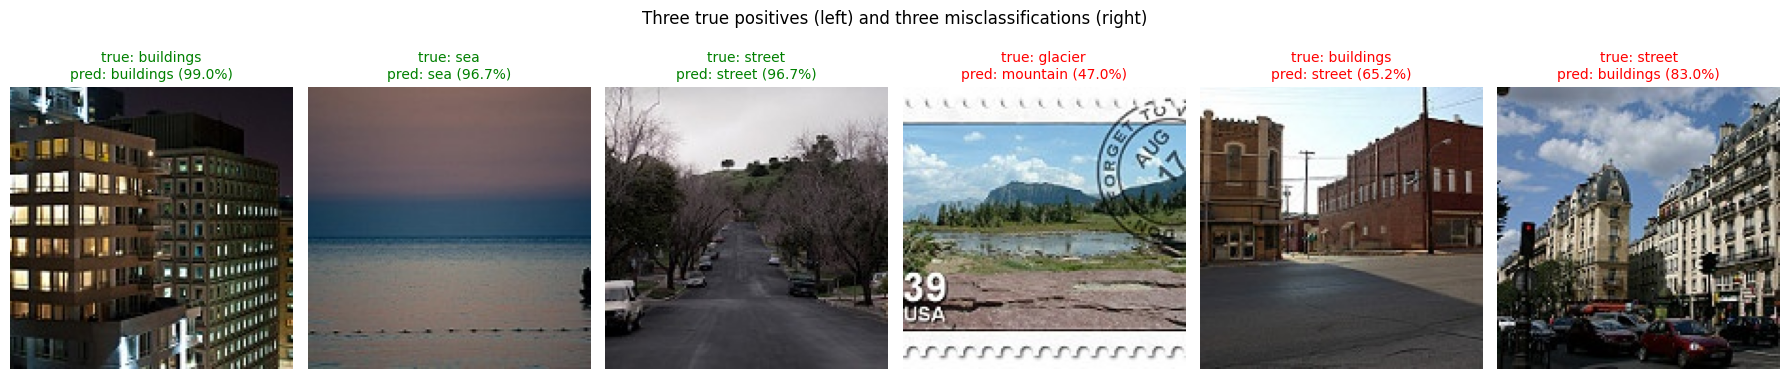

In [14]:
# ============================================================
# 6(a) Choose 3 true positives + 3 misclassified test images
# ============================================================
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx   = np.where(y_pred != y_true)[0]
print(f"Correct: {len(correct_idx)} | Misclassified: {len(wrong_idx)}")

rng = np.random.default_rng(SEED)

# 3 diverse, confident true positives (different classes)
tp_pool = sorted(correct_idx, key=lambda i: -y_prob[i, y_pred[i]])
tp_sel, seen = [], set()
for i in tp_pool:
    if y_true[i] not in seen:
        tp_sel.append(i); seen.add(y_true[i])
    if len(tp_sel) == 3:
        break

# 3 misclassifications, preferring the top-2 confused pairs
def in_top_pairs(i):
    a, b = CLASS_NAMES[y_true[i]], CLASS_NAMES[y_pred[i]]
    return any({a, b} == set(p) for p in TOP2_PAIRS)
mis_pref  = [i for i in wrong_idx if in_top_pairs(i)]
mis_other = [i for i in wrong_idx if not in_top_pairs(i)]
mis_sel = (list(rng.choice(mis_pref, size=min(3, len(mis_pref)), replace=False))
           + list(rng.choice(mis_other, size=3, replace=False)))[:3]

def load_test_img(i):
    img = cv2.cvtColor(cv2.imread(str(test_paths[i])), cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (IMG_SIZE, IMG_SIZE))

fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, i in zip(axes, tp_sel + list(mis_sel)):
    ax.imshow(load_test_img(i)); ax.axis("off")
    ok = y_pred[i] == y_true[i]
    ax.set_title(f"true: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]}"
                 f" ({y_prob[i, y_pred[i]]:.1%})",
                 color="green" if ok else "red", fontsize=10)
fig.suptitle("Three true positives (left) and three misclassifications (right)", y=1.06)
plt.tight_layout(); plt.savefig("fig_exemplars.png", dpi=200, bbox_inches="tight"); plt.show()

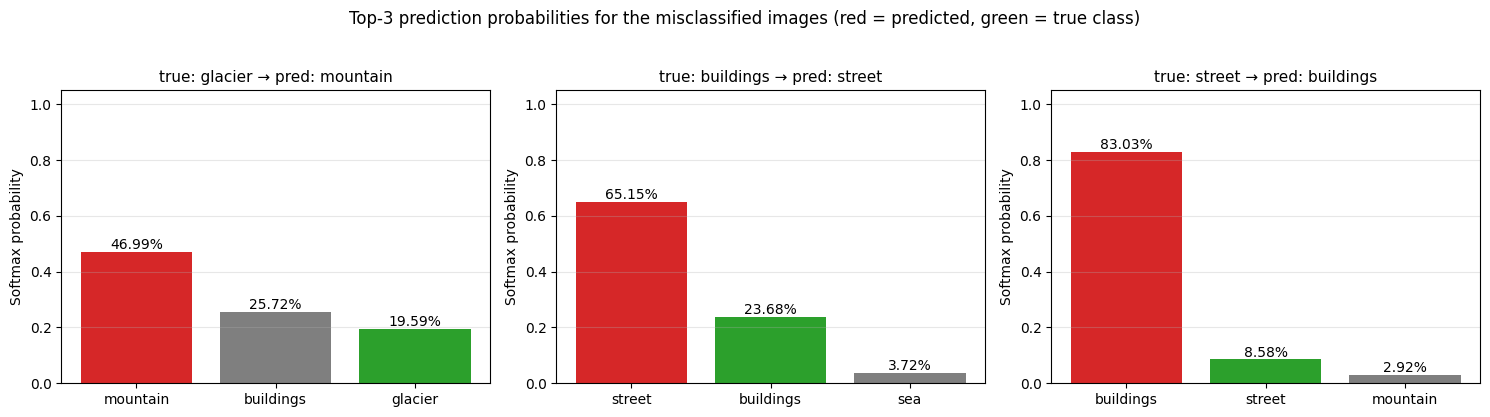

In [15]:
# ============================================================
# 6(a) continued — top-3 probability bar charts for the misclassifications
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, i in zip(axes, mis_sel):
    top3 = np.argsort(y_prob[i])[::-1][:3]
    colors = ["#d62728" if c == y_pred[i] else
              ("#2ca02c" if c == y_true[i] else "#7f7f7f") for c in top3]
    bars = ax.bar([CLASS_NAMES[c] for c in top3], y_prob[i][top3], color=colors)
    for b, c in zip(bars, top3):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                f"{y_prob[i][c]:.2%}", ha="center", fontsize=10)
    ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3)
    ax.set_title(f"true: {CLASS_NAMES[y_true[i]]} → pred: {CLASS_NAMES[y_pred[i]]}",
                 fontsize=11)
    ax.set_ylabel("Softmax probability")
fig.suptitle("Top-3 prediction probabilities for the misclassified images "
             "(red = predicted, green = true class)", y=1.03)
plt.tight_layout(); plt.savefig("fig_top3_probs.png", dpi=200, bbox_inches="tight"); plt.show()

### 6(b) Grad-CAM from scratch — the mathematics

**Grad-CAM** (Selvaraju et al., ICCV 2017) explains a prediction by asking: *which spatial locations of the final convolutional feature maps increased the score of the predicted class?* Let $A^k \in \mathbb{R}^{H\times W}$ be the $k$-th feature map of the target layer (here `gradcam_target`, the block-4 residual output, 18×18×256 pre-pooling) and $y^c$ the pre-softmax score for class $c$. Grad-CAM computes:

1. **Channel importance weights** by global-average-pooling the gradients:
$$\alpha_k^c = \frac{1}{HW}\sum_{i=1}^{H}\sum_{j=1}^{W} \frac{\partial y^c}{\partial A_{ij}^k}. \tag{7}$$

2. **A ReLU-rectified weighted combination** of the feature maps:
$$L^c_{\text{Grad-CAM}} = \mathrm{ReLU}\!\Big(\sum_k \alpha_k^c\, A^k\Big). \tag{8}$$

The ReLU keeps only locations whose increased activation *raises* the class score (positive evidence). The $H \times W$ map is min-max normalised, bilinearly upsampled to 150×150, passed through a jet colormap, and alpha-blended (α ≈ 0.4) onto the original image with OpenCV.

The implementation below builds a `keras.Model` mapping the input to *(target-layer activations, predictions)* and obtains $\partial y^c / \partial A^k$ with `tf.GradientTape` — no external libraries.

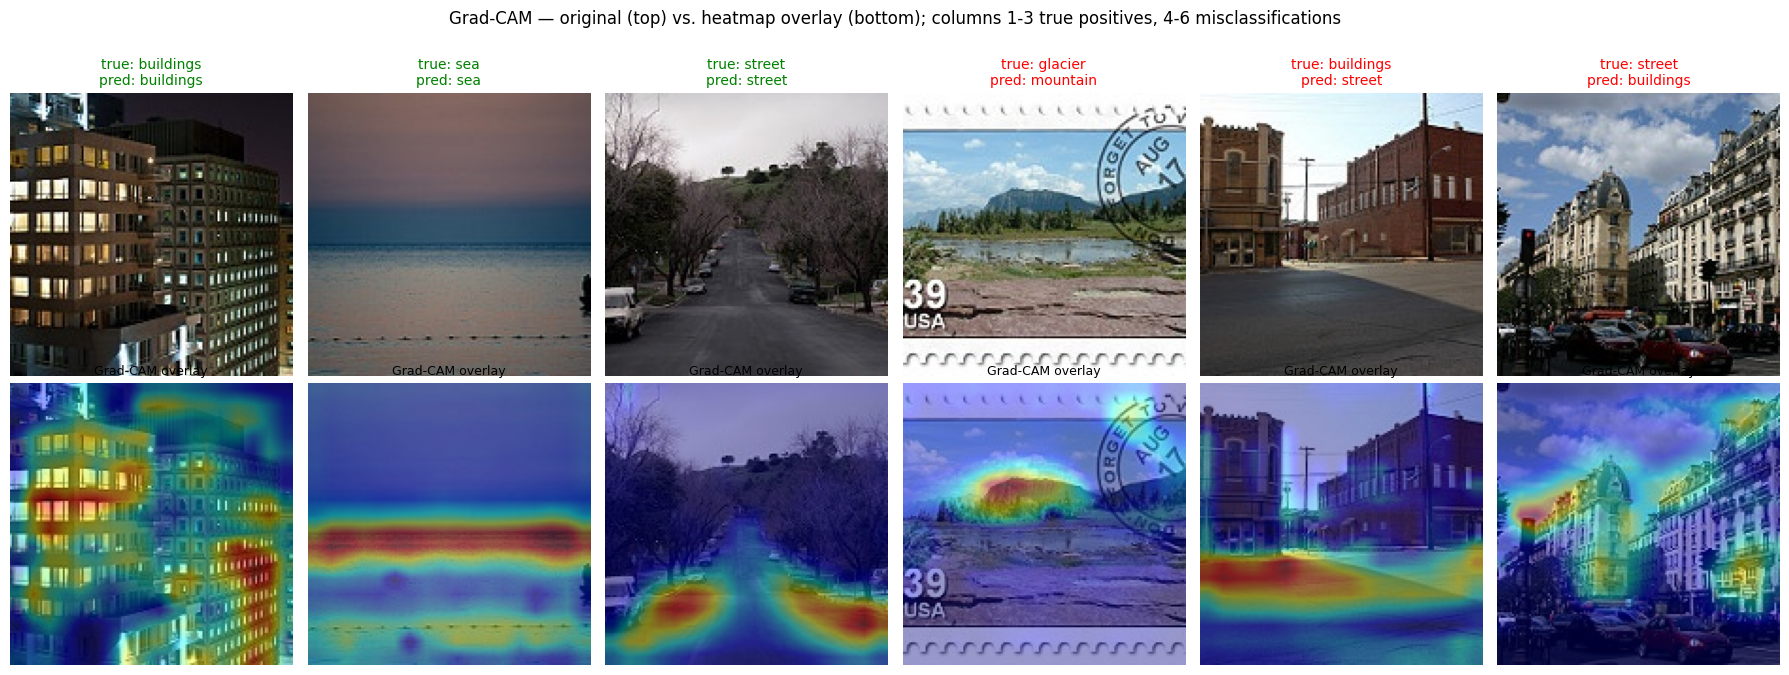

In [16]:
# ============================================================
# 6(b) Grad-CAM implementation (from scratch) + overlays for all 6 images
# ============================================================
grad_model = keras.Model(
    inputs=model.input,
    outputs=[model.get_layer("gradcam_target").output, model.output],
)

def grad_cam(img_float01, class_index):
    '''img_float01: (150,150,3) in [0,1]. Returns heatmap in [0,1] at IMG_SIZE.'''
    x = tf.convert_to_tensor(img_float01[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(x, training=False)
        class_score = preds[:, class_index]
    grads = tape.gradient(class_score, conv_out)          # ∂y^c/∂A  (1,H,W,K)
    alpha = tf.reduce_mean(grads, axis=(1, 2))            # eq. (7)  (1,K)
    cam = tf.einsum("bhwk,bk->bhw", conv_out, alpha)      # Σ_k α_k A^k
    cam = tf.nn.relu(cam)[0].numpy()                      # eq. (8)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cv2.resize(cam, (IMG_SIZE, IMG_SIZE))

def overlay(img_uint8, cam, alpha=0.4):
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return np.uint8((1 - alpha) * img_uint8 + alpha * heat)

sel = tp_sel + list(mis_sel)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.6))
for col, i in enumerate(sel):
    raw  = load_test_img(i)
    cam  = grad_cam(raw / 255.0, int(y_pred[i]))          # explain the *predicted* class
    ok   = y_pred[i] == y_true[i]
    axes[0, col].imshow(raw)
    axes[0, col].set_title(f"true: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]}",
                           color="green" if ok else "red", fontsize=10)
    axes[1, col].imshow(overlay(raw, cam))
    axes[1, col].set_title("Grad-CAM overlay", fontsize=9)
    for r in range(2):
        axes[r, col].axis("off")
fig.suptitle("Grad-CAM — original (top) vs. heatmap overlay (bottom); "
             "columns 1-3 true positives, 4-6 misclassifications", y=1.02)
plt.tight_layout(); plt.savefig("fig_gradcam.png", dpi=200, bbox_inches="tight"); plt.show()

### 6(c) Critique of the model's decisions (what the heatmaps show)

**True positives (columns 1–3).**
- *buildings*: activation sits on the lit window grid and façade edges, which is genuine class-defining structure.
- *sea*: activation forms a horizontal band along the horizon. The prediction is right, but it rests on a single compositional cue (a flat horizon line) that other classes can also contain.
- *street*: activation concentrates on the roadside edges and parked cars at the bottom of the frame rather than the road centre, which is plausible street evidence.

**Misclassifications (columns 4–6).**
- *glacier → mountain*: the image is a **postage stamp** showing a mountain and lake, not a glacier photograph, and the heatmap lands on the mountain. This looks like a **label or out-of-distribution problem** rather than a model failure; the model's answer is arguably defensible.
- *buildings → street*: activation sits on the road surface in the foreground, the region shared with street scenes.
- *street → buildings*: activation sits on the ornate building façades, which dominate the frame.

**Overall verdict.** The model mostly attends to semantic regions, and its errors follow the two confusion axes from Section 5(b): when the shared context (road, façade, mountain) dominates the frame, the network weights that context. Next steps: audit the test set for mislabelled or out-of-distribution images like the stamp, and test whether a pretrained backbone reduces context dominance (Section 8).

---
## Reproducibility & submission checklist

- ✅ Seeds fixed (`PYTHONHASHSEED`, `random`, `np.random.seed`, `tf.random.set_seed`) — note GPU op non-determinism means runs may still vary slightly.
- ✅ Functional API, 4 residual blocks with `Add()` skips (identity + 1×1 projections), BN throughout, SpatialDropout2D(0.3), Dropout(0.5), GAP head.
- ✅ Stratified 70/15/15 with printed balance table and disjointness `assert`s; augmentation on train only.
- ✅ AdamW (1e-3, wd 1e-4) + EarlyStopping(8, restore best) + ReduceLROnPlateau(0.5, 3, 1e-6) + ModelCheckpoint; ≤50 epochs.
- ✅ Classification report (per-class + macro/weighted), normalised confusion matrix, programmatic top-2 confused pairs, convergence-diagnosis helper.
- ✅ 3 TP + 3 misclassified with labels/confidences, top-3 probability bars, from-scratch Grad-CAM overlays.
- ✅ Narrative cells completed with this run's printed numbers.

---
## 7. Extension — Test-Time Augmentation (TTA)

*(This section goes beyond the assignment rubric; the Section 5 metrics remain the primary reported results.)*

**Idea.** The horizontal-flip invariance we *taught* the model through training augmentation can also be *exploited* at inference: predict each test image twice — original and mirrored — and average the softmax distributions. Averaging over transformed views reduces the variance of the prediction (an implicit 2-member ensemble at zero training cost) and typically recovers a few tenths of a point of accuracy. We report TTA accuracy **alongside**, not instead of, the standard single-view metrics, to keep the primary evaluation protocol clean.

In [17]:
# ============================================================
# 7. Test-time augmentation: average softmax over {original, h-flip}
# ============================================================
images_only = test_ds.map(lambda x, y: x)
y_prob_flip = model.predict(images_only.map(lambda x: tf.image.flip_left_right(x)),
                            verbose=0)
y_prob_tta = (y_prob + y_prob_flip) / 2.0
y_pred_tta = np.argmax(y_prob_tta, axis=1)

acc_tta = float(np.mean(y_pred_tta == y_true))
from sklearn.metrics import f1_score
print(f"Standard accuracy : {np.mean(y_pred == y_true):.4%}   "
      f"macro F1: {f1_score(y_true, y_pred, average='macro'):.4f}")
print(f"TTA accuracy      : {acc_tta:.4%}   "
      f"macro F1: {f1_score(y_true, y_pred_tta, average='macro'):.4f}")
print(f"TTA changed {int(np.sum(y_pred_tta != y_pred))} predictions.")

Standard accuracy : 84.4679%   macro F1: 0.8455
TTA accuracy      : 84.7418%   macro F1: 0.8484
TTA changed 33 predictions.


## 8. Extension — Transfer-Learning Benchmark: fine-tuned EfficientNetB0

*(This section is a benchmark **comparison**, not a replacement for the custom model: the assignment explicitly requires a custom Functional-API architecture, which Sections 3–6 deliver and which remains the primary submission. Here we quantify the gap to ImageNet-pretrained representations — precisely the "future work" a rigorous study should execute.)*

**Protocol.** An **EfficientNetB0** backbone pretrained on ImageNet is attached to the *identical* stratified split and evaluated with the *identical* test protocol, so the comparison is apples-to-apples. Because EfficientNet's built-in preprocessing expects raw [0, 255] inputs at 224×224, the model internally rescales (×255) and resizes our [0,1] 150×150 pipeline tensors — the shared tf.data pipeline is untouched. Training follows the standard two-phase recipe:

1. **Feature extraction** — backbone frozen, train only the new head (3 epochs, Adam 1e-3);
2. **Fine-tuning** — unfreeze the backbone with BatchNorm layers kept in inference mode, and train end-to-end at a very low learning rate (up to 6 epochs, AdamW 1e-5, EarlyStopping patience 2) so the pretrained features are gently adapted rather than destroyed.

In [18]:
# ============================================================
# 8. EfficientNetB0: build, two-phase train, evaluate on the same split
# ============================================================
def build_effnet(num_classes=NUM_CLASSES):
    base = keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    base.trainable = False

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_image")
    x = layers.Rescaling(255.0, name="to_0_255")(inputs)      # EffNet expects [0,255]
    x = layers.Resizing(224, 224, name="to_224")(x)
    x = base(x, training=False)                                # BN in inference mode
    x = layers.GlobalAveragePooling2D(name="tl_gap")(x)
    x = layers.Dropout(0.3, name="tl_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="tl_predictions")(x)
    return keras.Model(inputs, outputs, name="EffNetB0_transfer"), base

tl_model, tl_base = build_effnet()

# ---- Phase 1: feature extraction (frozen backbone) ----
tl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
                 metrics=["accuracy"])
print("Phase 1 — frozen backbone:")
tl_model.fit(train_ds, validation_data=val_ds, epochs=3, verbose=1)

# ---- Phase 2: gentle end-to-end fine-tuning ----
tl_base.trainable = True          # base(x, training=False) keeps BN stats frozen
tl_model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-5, weight_decay=1e-5),
                 loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
                 metrics=["accuracy"])
print("\nPhase 2 — fine-tuning:")
tl_model.fit(train_ds, validation_data=val_ds, epochs=6, verbose=1,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                                      restore_best_weights=True)])

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Phase 1 — frozen backbone:
Epoch 1/3
373/373 ━━━━━━━━━━━━━━━━━━━━ 146s 303ms/step - accuracy: 0.8426 - loss: 0.7749 - val_accuracy: 0.9092 - val_loss: 0.6377
Epoch 2/3
373/373 ━━━━━━━━━━━━━━━━━━━━ 85s 209ms/step - accuracy: 0.8912 - loss: 0.6734 - val_accuracy: 0.9166 - val_loss: 0.6215
Epoch 3/3
373/373 ━━━━━━━━━━━━━━━━━━━━ 81s 206ms/step - accuracy: 0.8996 - loss: 0.6581 - val_accuracy: 0.9190 - val_loss: 0.6158

Phase 2 — fine-tuning:
Epoch 1/6
373/373 ━━━━━━━━━━━━━━━━━━━━ 222s 375ms/step - accuracy: 0.7853 - loss: 0.9372 - val_accuracy: 0.8579 - val_loss: 0.7925
Epoch 2/6
373/373 ━━━━━━━━━━━━━━━━━━━━ 104s 230ms/step - accuracy: 0.8579 - loss: 0.7611 - val_accuracy: 0.8712 - val_loss: 0.7547
Epoch 3/6
373/373 ━━━━━━━━━━━━━━━━━━━━ 86s 226ms/step - accuracy: 0.8788 - loss: 0.7138 - val_accuracy: 0.8830 - val_loss: 0.7230
Epoch 4/6
373/373 ━━━━━━━━━━━━━━━━━━━━ 143s 229ms/step - accuracy: 0.8840 - loss: 0.6964 - val_accuracy: 0.8955 - v

In [ ]:
# ============================================================
# 8 continued — head-to-head comparison on the identical test set
# ============================================================
tl_prob = tl_model.predict(test_ds, verbose=0)
tl_pred = np.argmax(tl_prob, axis=1)
tl_acc  = float(np.mean(tl_pred == y_true))
tl_f1   = f1_score(y_true, tl_pred, average="macro")

custom_acc = float(np.mean(y_pred == y_true))
custom_f1  = f1_score(y_true, y_pred, average="macro")

comp = pd.DataFrame({
    "Model": ["ResScene-CNN v2 (custom, this work)",
              "ResScene-CNN v2 + TTA",
              "EfficientNetB0 (fine-tuned, benchmark)"],
    "Params": [f"{model.count_params():,}", f"{model.count_params():,}",
               f"{tl_model.count_params():,}"],
    "Test accuracy": [f"{custom_acc:.4%}", f"{acc_tta:.4%}", f"{tl_acc:.4%}"],
    "Macro F1": [f"{custom_f1:.4f}",
                 f"{f1_score(y_true, y_pred_tta, average='macro'):.4f}",
                 f"{tl_f1:.4f}"],
})
display(comp)

# Per-class recall comparison — does ImageNet knowledge fix the glacier problem?
from sklearn.metrics import recall_score
rec = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Custom recall": recall_score(y_true, y_pred, average=None).round(4),
    "EffNetB0 recall": recall_score(y_true, tl_pred, average=None).round(4),
})
display(rec)
comp.to_csv("model_comparison.csv", index=False)

,Model,Params,Test accuracy,Macro F1
0,"ResScene-CNN v2 (custom, this work)","1,309,794",84.4679%,0.8455
1,ResScene-CNN v2 + TTA,"1,309,794",84.7418%,0.8484
2,"EfficientNetB0 (fine-tuned, benchmark)","4,057,257",90.1017%,0.9009


,Class,Custom recall,EffNetB0 recall
0,buildings,0.9239,0.9340
1,forest,0.9563,0.9757
2,glacier,0.7477,0.6892
3,mountain,0.8158,0.9386
4,sea,0.9137,0.9664
5,street,0.7298,0.9145
